In [1]:
import pandas as pd
import numpy as np

In [3]:
df= pd.read_csv("/content/P2-Healthcare Analytics for Doctor Visits.csv")

In [4]:
df.shape

(5190, 13)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5190 entries, 0 to 5189
Data columns (total 13 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  5190 non-null   int64  
 1   visits      5190 non-null   int64  
 2   gender      5190 non-null   object 
 3   age         5190 non-null   float64
 4   income      5190 non-null   float64
 5   illness     5190 non-null   int64  
 6   reduced     5190 non-null   int64  
 7   health      5190 non-null   int64  
 8   private     5190 non-null   object 
 9   freepoor    5190 non-null   object 
 10  freerepat   5190 non-null   object 
 11  nchronic    5190 non-null   object 
 12  lchronic    5190 non-null   object 
dtypes: float64(2), int64(5), object(6)
memory usage: 527.2+ KB


In [8]:
df.describe()

,Unnamed: 0,visits,age,income,illness,reduced,health
count,5190.000000,5190.000000,5190.000000,5190.000000,5190.000000,5190.000000,5190.000000
mean,2595.500000,0.301734,0.406385,0.583160,1.431985,0.861850,1.217534
std,1498.368279,0.798134,0.204782,0.368907,1.384152,2.887628,2.124266
min,1.000000,0.000000,0.190000,0.000000,0.000000,0.000000,0.000000
25%,1298.250000,0.000000,0.220000,0.250000,0.000000,0.000000,0.000000
50%,2595.500000,0.000000,0.320000,0.550000,1.000000,0.000000,0.000000
75%,3892.750000,0.000000,0.620000,0.900000,2.000000,0.000000,2.000000
max,5190.000000,9.000000,0.720000,1.500000,5.000000,14.000000,12.000000


In [6]:
df.isnull().sum()

,0
Unnamed: 0,0
visits,0
gender,0
age,0
income,0
illness,0
reduced,0
health,0
private,0
freepoor,0


### Univariate Plots

Let's visualize the distribution of some key variables in the dataset using univariate plots. This helps in understanding the range, central tendency, and spread of individual features.

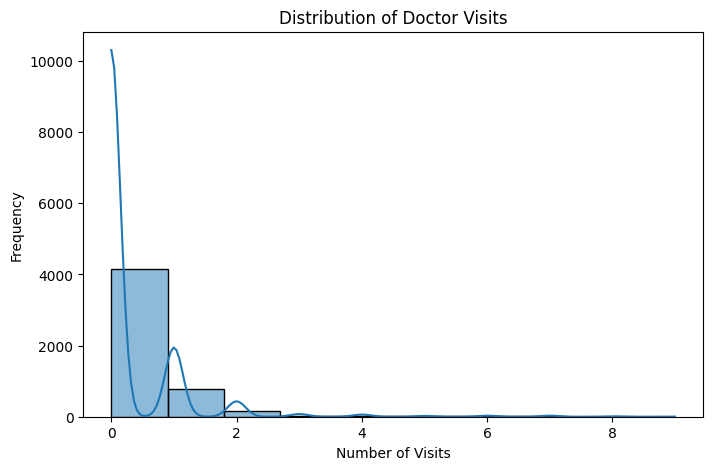

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# Plot 1: Distribution of 'visits'
plt.figure(figsize=(8, 5))
sns.histplot(df['visits'], bins=10, kde=True)
plt.title('Distribution of Doctor Visits')
plt.xlabel('Number of Visits')
plt.ylabel('Frequency')
plt.show()

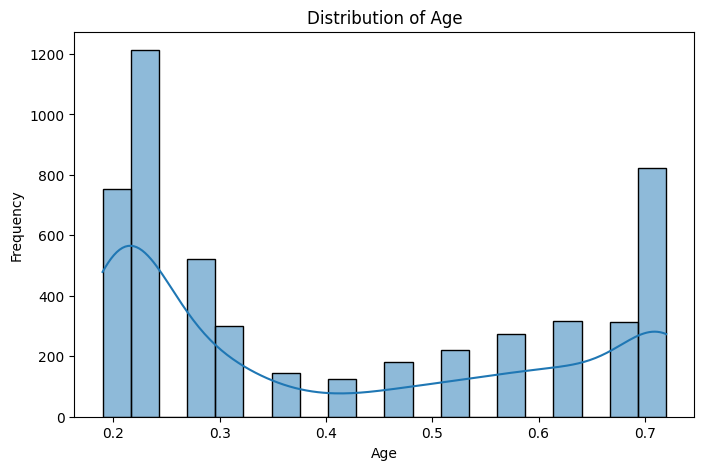

In [10]:
# Plot 2: Distribution of 'age'
plt.figure(figsize=(8, 5))
sns.histplot(df['age'], bins=20, kde=True)
plt.title('Distribution of Age')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()

/tmp/ipykernel_1739/2798768331.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='gender', data=df, palette='viridis')


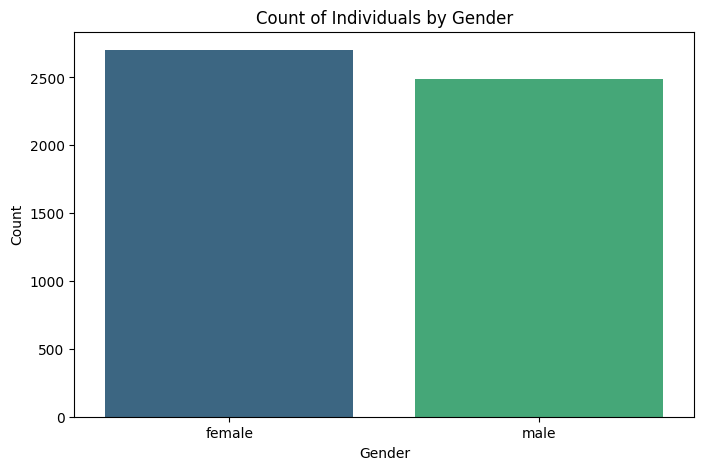

In [12]:
# Plot 3: Count of 'gender'
plt.figure(figsize=(8, 5))
sns.countplot(x='gender', data=df, palette='viridis')
plt.title('Count of Individuals by Gender')
plt.xlabel('Gender')
plt.ylabel('Count')
plt.show()

### Multivariate Plots

Now, let's explore relationships between multiple variables using multivariate plots. This helps in understanding how different features might interact or influence each other.

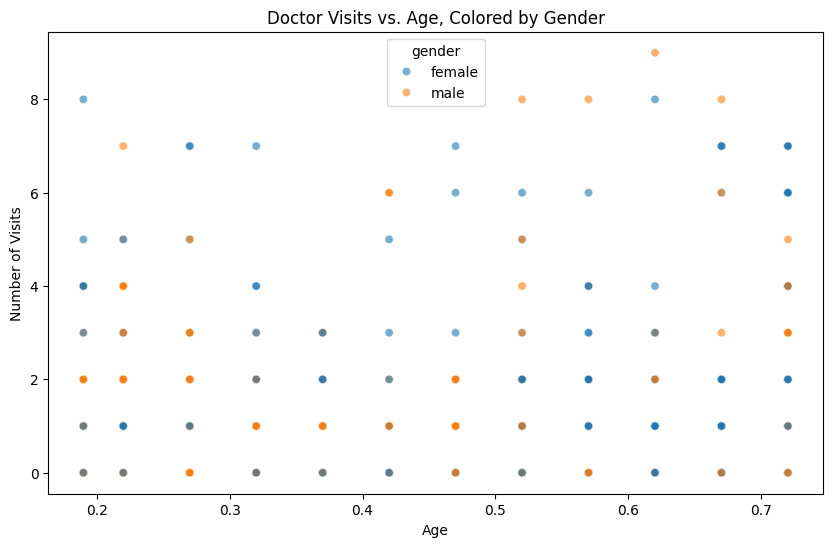

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

# Plot 1: Scatter plot of 'age' vs 'visits'
plt.figure(figsize=(10, 6))
sns.scatterplot(x='age', y='visits', data=df, hue='gender', alpha=0.6)
plt.title('Doctor Visits vs. Age, Colored by Gender')
plt.xlabel('Age')
plt.ylabel('Number of Visits')
plt.show()

/tmp/ipykernel_1739/934983449.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='gender', y='visits', data=df, palette='pastel')


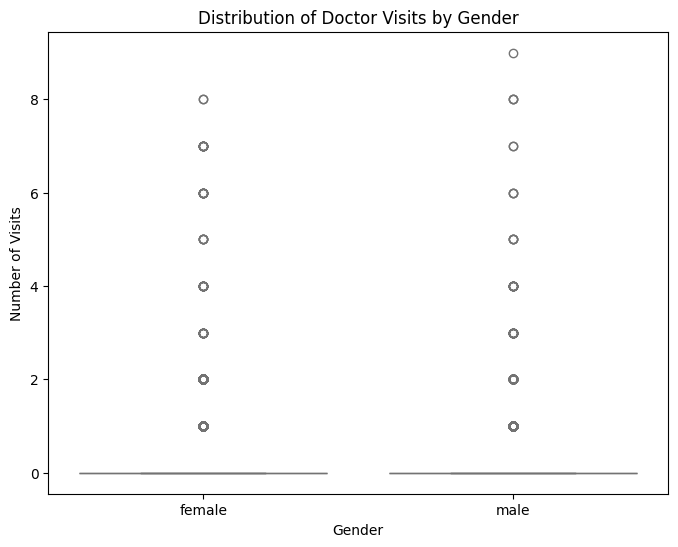

In [14]:
# Plot 2: Box plot of 'visits' by 'gender'
plt.figure(figsize=(8, 6))
sns.boxplot(x='gender', y='visits', data=df, palette='pastel')
plt.title('Distribution of Doctor Visits by Gender')
plt.xlabel('Gender')
plt.ylabel('Number of Visits')
plt.show()

,illness,count,mean
0,0,1554,0.078507
1,1,1638,0.295482
2,2,946,0.403805
3,3,542,0.420664
4,4,274,0.576642
5,5,236,0.813559


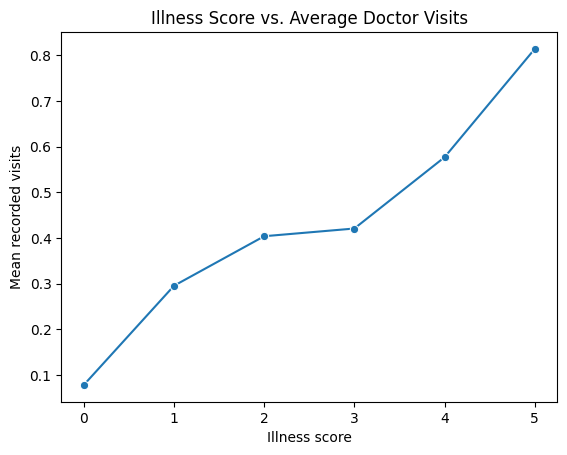

In [15]:
illness_analysis = (
    df.groupby("illness")["visits"]
      .agg(["count", "mean"])
      .reset_index()
)

display(illness_analysis)

sns.lineplot(
    data=illness_analysis,
    x="illness",
    y="mean",
    marker="o"
)

plt.title("Illness Score vs. Average Doctor Visits")
plt.xlabel("Illness score")
plt.ylabel("Mean recorded visits")
plt.show()

### Line Plot: Average Visits by Age

To visualize a trend, let's plot the average number of visits as age increases. This can reveal if there's a general pattern of doctor visits across different age groups.

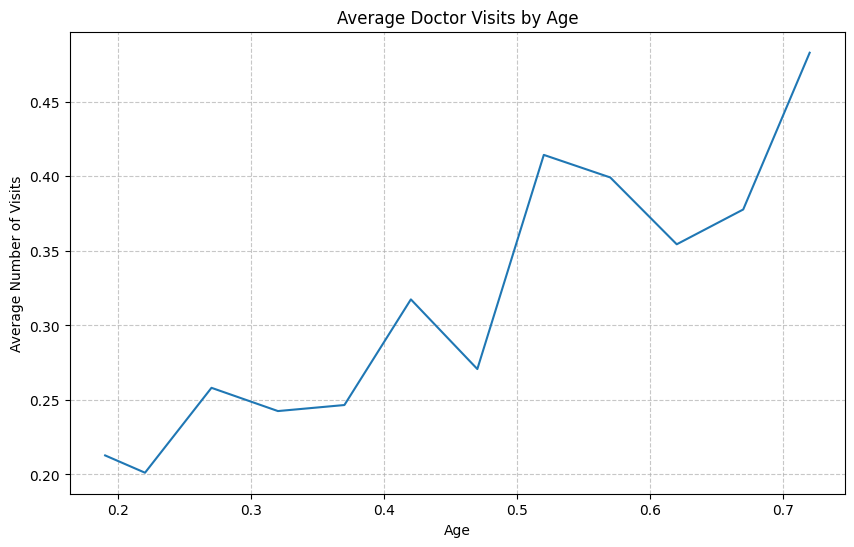

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate the average number of visits for each age
average_visits_by_age = df.groupby('age')['visits'].mean().reset_index()

# Plotting the line plot
plt.figure(figsize=(10, 6))
sns.lineplot(x='age', y='visits', data=average_visits_by_age)
plt.title('Average Doctor Visits by Age')
plt.xlabel('Age')
plt.ylabel('Average Number of Visits')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()